# SQDMetal floating-transmon Palace example — tapered-inset transmon with a λ/2 readout (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/Palace_Eigenmode_FloatingTransmon.ipynb`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/floating_transmon.md`): a
Quantum Metal design (SQDMetal `TransmonTaperedInsets` + Metal `CoupledLineTee`, `RouteMeander`, `RouteStraight`,
`OpenToGround`) for a Palace eigenmode run (3 modes from 3 GHz, silicon 500 µm); no stored outputs. One floating
tapered-pad transmon whose readout connector pad runs a **λ/2 meander** (6.8 GHz on Si, 8.96 mm) to a
`CoupledLineTee` with an **open** termination (220 µm coupled, 5 µm ground strip) on a short straight line between
two open ends (the simulation adds 50 Ω ports there). Target f_q 4.5 GHz.

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | Metal chip 4 × 4 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with its frame, device ID "SQD-FT" (Designer = source + (2000, 2000) µm before centring) |
| line ends / pads | two `OpenToGround`s at x = −1.8 / 0 mm (Palace ports) | two small `BondPad`s (100 × 100 µm) as the line's 50 Ω ports, **on the die edges** (outer etch 100 µm, `frame.pad_edge`, from the west / east edge, PDK pad rule): the line is 6.9 mm instead of 1.8 mm |
| substrate | silicon, 500 µm | sapphire 650 µm, εr 10.25 |
| junction | a junction line, L_J not given (target 4.5 GHz) | the Quantcore trilayer junction **sized for the target 4.5 GHz**: 0.31 × 0.6 µm, L_J ≈ 10.9 nH — R_n ≈ 72 kΩ, ⚠ above the 40–50 kΩ window (a 45 kΩ junction would give ≈ 5.6 GHz) |
| cheese | none (`MakeGDS(design).export(..., export_type="positive")` — SQDMetal's exporter perforates the ground only through an explicit `perforate_layer`, which the example never calls) | the PDK band (chip `cheese` `"auto"`, at least 4 µm clear of 3/0) |
| components | `TransmonTaperedInsets`, `CoupledLineTee` + `RouteMeander` | Quantcore re-implementation of `TransmonTaperedInsets` (Apache-2.0) with the source options; the tee + meander as one qcc open hanger route |
| placement | — | centred in the die (the content sat ≈ 710 µm north of the centre; moved south. In x the pads on both edges span the die, so no x shift) |

**Kept:** the λ/2 length 8960 µm counted as in the source (connector wire 410 µm inside the cell + route 8550 µm),
the 220 µm / 5 µm coupled section at the source's position, meander spacing ≈ 100 µm (r = 40 µm, the source
fillet), the targets (f_q 4.5 GHz, f_r 6.8 GHz on Si) and the sim group.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; set it to `True` to solve the jobs in a new batch
AEDT 2024 R1 (if one is installed). `FULL_FAB = False` skips the fab-only corner rounding in the mask step
(`qcc mask` writes the complete file). Step snapshots go to `build/snapshots/` (not kept in the repo); the final
ones next to the notebook.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "floating_transmon"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 2000, 2000                              # Metal's 4 × 4 mm chip is centred on (0, 0)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** The source's target f_q is 4.5 GHz. `size_junction(4.5, C_Σ)` solves the
trilayer junction on the PDK rule (Nb Δ 1.4 meV, R_n·A 13.5 kΩ·µm², C_J 50 fF/µm²) for the qubit's C_Σ (97.9 fF
without the junction, from this design's LOM before the rebuild: f_q 4.10 GHz with 14 nH, C_J 0). The result is a
0.31 × 0.6 µm junction, L_J ≈ 10.9 nH, C_J ≈ 9.3 fF — **R_n ≈ 72 kΩ, outside the 40–50 kΩ window**; the sizing line
prints the note. Kept: the target is the source's (values outside the PDK margins are flagged, not retuned).
`trilayer_junction` turns L_J into the cell's `junction_type` + `junction_params`.

In [4]:
from quantcore_circuits.circuit.bridges import size_junction
SIZED = size_junction(4.5, 97.9, c_includes_junction=False)
JJ_PARAMS, JUNCTION = trilayer_junction("TransmonTaperedInsets", lj_nH=SIZED.lj_nH)
print(JUNCTION, f"R_n {SIZED.rn_kohm:.0f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)

{'Lj_nH': 10.862, 'Cj_fF': 9.3} R_n 72 kΩ, fingers 0.31 × 0.6 µm; R_n 72.0 kΩ is outside the process window 40–50 kΩ (f_q 4.5 GHz with C_Σ 107.3 fF needs E_J/h 15.2 GHz)


## 3 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so the source's 4 × 4 mm area sits
in its middle (every source position + (2000, 2000) µm). The PDK frame: L dicing markers (1000/0), 3 × 3 alignment
grids (1001/0), the chip boundary (100/0), the device ID on a free edge. The chip `cheese` stays `"auto"`: the
source has no cheese, so the PDK band is drawn.

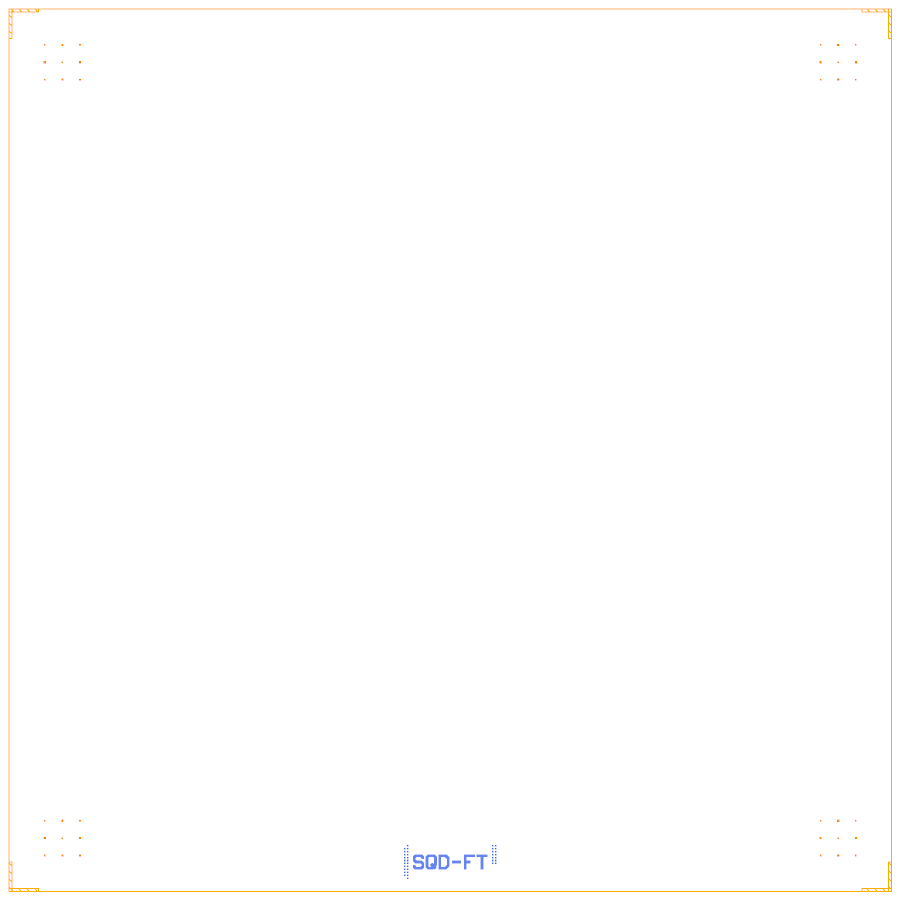

In [5]:
d = Designer("floating_transmon", box=(-1750, -1750, 5750, 5750), chip={"name_chip": "SQD-FT"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(900, 900), width=360);

## 4 · Pads and the pad rule

The source's line ends are open (`OpenToGround`), and Palace adds 50 Ω ports there; our LOM needs real ports, so
two small `BondPad`s (100 × 100 µm pad, 50 µm taper, 30 µm gap) terminate the line. **PDK rule:** a pad's outer
etch edge sits `frame.pad_edge` (100 µm) from the die edge, so the pads go on the line's y with
`edge="w"` / `edge="e"`: each slides perpendicular to its edge until its etch is 100 µm from it.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_L | `BondPad` | w | 100.0 | ✓ |
| P_R | `BondPad` | e | 100.0 | ✓ |

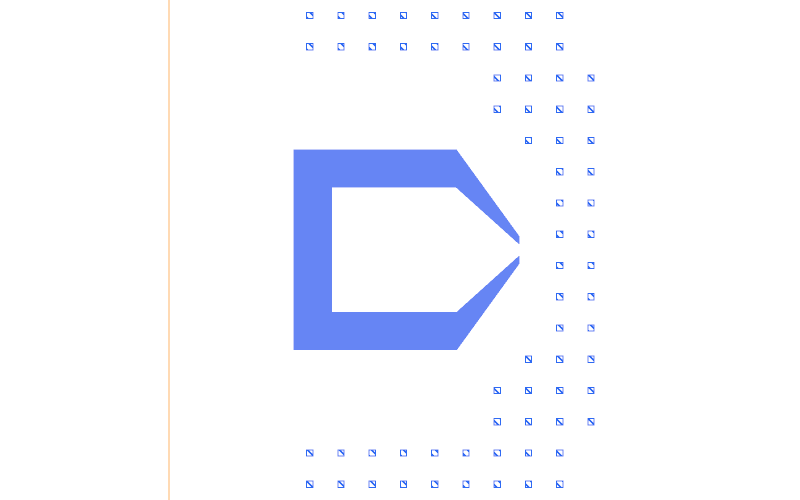

In [6]:
PAD = dict(pad_width=100, pad_height=100, taper_length=50, pad_gap=30)
with d.batch():
    pl = d.add("P_L", "BondPad", at=(X0 - 1800, Y0), rot=270, edge="w", **PAD)   # the source's otg_left end
    pr = d.add("P_R", "BondPad", at=(X0, Y0), rot=90, edge="e", **PAD)            # otg_right
rebuild(d)
display(Markdown(pads_md(d)))
x, y = port_xy(d, "P_L.a")
snap(d, STEPS / "2_pad.png", box=(-1760, y - 200, x + 100, y + 200), size=(800, 500), width=360);

## 5 · Components

**The qubit:** `TransmonTaperedInsets`, Quantcore's re-implementation of SQDMetal's cell (Apache-2.0), with the
source options: two 800 × 110 µm pads 100 µm apart, `taper_height` 0, a 100 µm junction line, the 1000 × 800 µm
pocket, orientation 90°, and the `readout` connection pad (200 × 30 µm, 100 µm beyond the pad) whose wire ends at
SQDMetal's pin, 700 µm from the centre. The trilayer junction from step 2 is drawn across the pad gap
(`junction_params`). Ports: `readout`, the SQDMetal placement pins (`top_*_pin`, `bottom_*_pin`, `*_pocket_pin`,
marks for charge lines or capacitors) and the junction attachment points `squid_a` / `squid_b`.

<TransmonTaperedInsets Q1 ports=['bottom_left_pin', 'bottom_pocket_pin', 'bottom_right_pin', 'readout', 'squid_a', 'squid_b', 'top_left_pin', 'top_pocket_pin', 'top_right_pin']>


Q1.readout (x, y, direction): (1800.0, 3000.0, 180.0)


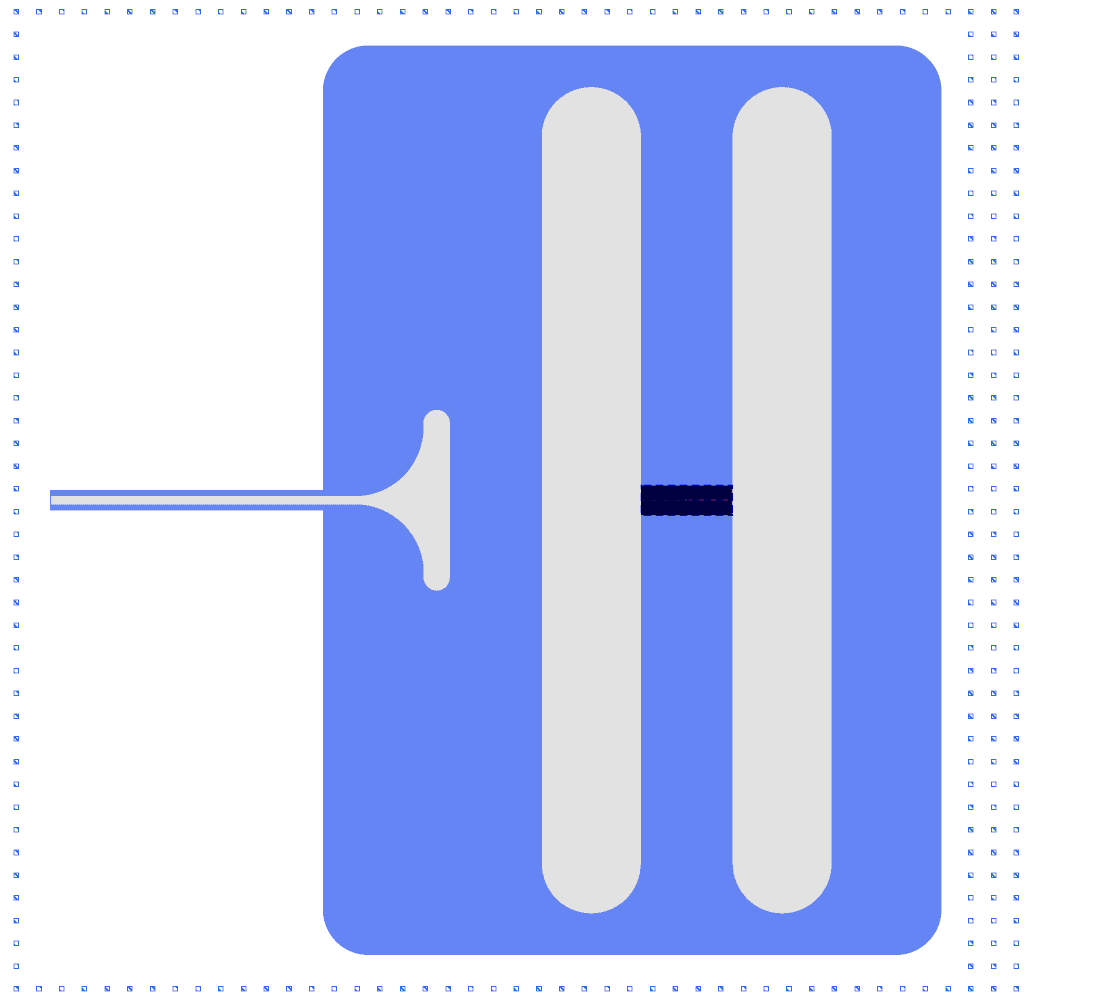

In [7]:
TTI = dict(connection_pads={"readout": {"pad_gap": 100}}, inductor_height=100, pad_gap=100, taper_height=0)  # source options
WIRE = 410.0                                     # SQDMetal readout_wire (connection pad top at 290 µm → pin at 700 µm)
q1 = d.add("Q1", "TransmonTaperedInsets", at=(X0 + 500, Y0 + 1000), rot=90, junction=JUNCTION, **JJ_PARAMS, **TTI)
print(q1)
print("Q1.readout (x, y, direction):", port_info(d, "Q1.readout"))
snap(d, STEPS / "3_qubit.png", box=(X0 - 250, Y0 + 450, X0 + 950, Y0 + 1550), size=(1100, 1000), width=400);

## 6 · Routes

**The line** `FL` between the two pads (10/6 µm, straight).

**The readout** (λ/2, 8960 µm including the 410 µm connector wire inside the cell): readout pin → meander (KQC's,
9 turns, r = 40 µm) → the 220 µm coupled section with a 5 µm ground strip → an **open** end at its west end
(`end="open"`, `direction="backward"`). `FL.hanger(near=(x, y), ...)` centres the coupled section at the line
point nearest (1000, y_FL) — the source's `CoupledLineTee` position, independent of where the line starts (it now
starts ≈ 1.7 mm further west, at the west pad).

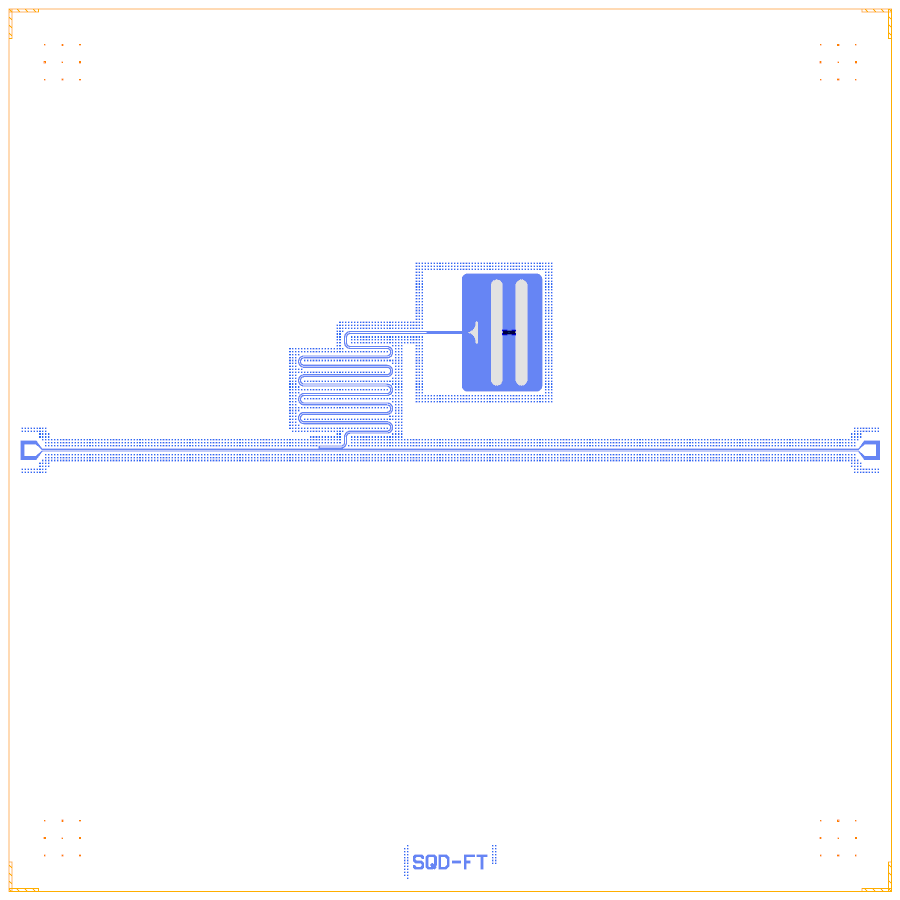

{'FL': 6940.0, 'R1': 8550.0}


In [8]:
with d.batch():
    fl = d.route("FL", pl.a, pr.a)
    d.route("R1", q1.readout, fl.hanger(near=(X0 - 1000, Y0), length=220, side="left", ground_gap=5,
                                        direction="backward", end="open"), meander=8960 - WIRE, r=40).set(meanders=9)
snap(d, STEPS / "4_routes.png", size=(900, 900), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Targets, sim group, centring, save.** The source's targets (f_q 4.5 GHz, f_r 6.8 GHz on silicon) go into the
design; one sim group holds the qubit, its readout and the line (a Q3D C-matrix and an eigenmode / EPR job, the
source's own run being a Palace eigenmode). `center_in_die` applies the PDK placement rule: with the pads on the
edges the content spans the die in x, but it sat ≈ 710 µm north of the centre (the qubit above the line), so
everything moves south (instance positions, the hanger's `near` point; the pads stay on their edges). Then the
design is saved.

In [9]:
d.targets(Q1={"f_q_GHz": 4.5}, R1={"f_GHz": 6.8})
d.sim_group("Q1R1", ["Q1", "R1", "FL"])
DX, DY = center_in_die(d)
print("centring shift (µm):", (DX, DY))
rebuild(d)
DESIGN = d.save(OUT / "floating_transmon.json")
print(d, "→", DESIGN, "| R1", round(d.result.route_lengths()["R1"], 1), "µm")

centring shift (µm): (0.0, -710.0)
<Designer floating_transmon: 3 instances, 2 routes, live=False> → examples\designs\sqdmetal\floating_transmon.json | R1 8550.0 µm


## 7 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here: **no errors**; `dangling_port` warnings for the `TransmonTaperedInsets` placement pins
(`top_*_pin`, `bottom_*_pin`, `*_pocket_pin`: SQDMetal's marks for charge lines or capacitors, not CPW ends; the
source uses none here) and the junction attachment points `squid_a` / `squid_b`. One PDK design warning: `pdk_rn`
on Q1 (R_n ≈ 72 kΩ, sized for the source's 4.5 GHz target; flagged, not retuned).

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 8 warnings · 1 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.bottom_left_pin is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 1 | Q1: junction R_n 72.6 kΩ is outside the PDK window 40–50 kΩ (L_J 10.862 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | Q1: junction R_n 72.6 kΩ is outside the PDK window 40–50 kΩ (L_J 10.862 nH) |

## 8 · Netlist and LOM

`d.lom()` maps the ports onto circuit nodes. `TransmonTaperedInsets` is a floating transmon: two pad nodes with
C to ground and between them, the junction across them, and the readout connection pad with its 410 µm wire as one
node (C to ground and to the near pad), so the wire loads the λ/2 as a lumped C. The readout is a λ/2 `TLres`
(claw at one end, open at the other); its open coupled section is a `HANGER` κ element to the line node, and the
two pads are the line's 50 Ω ports. The netlist lists the six placement pins as unconnected (nothing attaches
there).

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1 / R1 ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("Q1.readout", "Q1.squid", "R1")))))

**5 nodes · 10 branches · 0 controls · 6 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `P_L.pad`, `P_R.pad` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.cp_readout` | `Q1.readout` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_L` | R | `FL` – `gnd` | 50 Ω |
| `Port_P_R` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 92.7 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 106 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 44.4 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 10.9 nH, Cj 9.3 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.cp_readout` | 13 fF |
| `Cc_Q1_readout` | C | `Q1.cp_readout` – `gnd` | 73 fF |
| `R1` | TLres | `Q1.cp_readout` – `gnd` | lambda/2, 8550 µm, 7.370 GHz |
| `K_R1` | HANGER | `Q1.cp_readout` – `FL` | κ 0.0103 MHz (L 220 µm) |

**Unconnected ports:** `Q1.bottom_left_pin`, `Q1.bottom_pocket_pin`, `Q1.bottom_right_pin`, `Q1.top_left_pin`, `Q1.top_pocket_pin`, `Q1.top_right_pin`

**Q1 / R1 ports → circuit nodes:**

| port | node |
|---|---|
| `Q1.readout` | `Q1.cp_readout` |
| `Q1.squid_a` | `Q1.island1` |
| `Q1.squid_b` | `Q1.island2` |

## 9 · LOM simulation

QuCat normal modes of the whole circuit (frequencies, κ into the two 50 Ω pads, anharmonicities), then the
QuTiP-dressed values next to the source's targets (f_q 4.5 GHz, λ/2 6.8 GHz — on silicon; this rebuild is on
sapphire, so the readout lands a little higher). Expected: f_q ≈ 4.5 GHz (the junction was sized for it),
α ≈ −180 MHz, f_r ≈ 6.9 GHz with a small κ from the 220 µm open coupled section.

In [12]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res, {"Q1": {"f_q_GHz": 4.5}, "R1": {"f_GHz": 6.8}})))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 4.6755 | 1.48e-06 | 181.3 | J_Q1 1.00 |
| R1 | resonator | 6.9070 | 0.00792 | 0.0 | R1 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 4.4861 | 4.5 |
| `Q1.alpha_MHz` | -200.76 | – |
| `R1.chi_MHz` | -0.41104 | – |
| `R1.f_GHz` | 6.9068 | 6.8 |
| `R1.kappa_MHz` | 0.0079237 | – |

## 10 · FEM: send the jobs
The LOM uses analytic capacitance estimates; a finite-element job measures them. `send_fem_jobs` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, each Ansys job is solved in a **new batch,
non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [13]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · eigenmode_epr | `build/jobs/floating_transmon_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · lumped · `P_L.pad`<br>3 · lumped · `P_R.pad` | `Q1.island1`, `P_L.pad`, `Q1.readout`, `Q1.island2` |
| Q1R1 · q3d_cmatrix | `build/jobs/floating_transmon_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.readout`<br>3 · lumped · `P_L.pad`<br>4 · lumped · `P_R.pad` | `Q1.island1`, `Q1.readout`, `P_L.pad`, `Q1.island2` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`:
the C-matrix replaces the component estimates branch by branch (matched by net name), and the table compares the two;
`simulate(filled)` re-runs the LOM on the extracted values. Until a solve has run, the cell says which jobs are still
waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1R1 · eigenmode_epr, Q1R1 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

Shorten the readout by 500 µm (route 8550 → 8050 µm, λ/2 8960 → 8460 µm): f_r rises by ≈ 6 % (≈ +0.4 GHz), the
qubit–readout detuning grows and |χ| drops. Done on a copy (`design_copy`), so `floating_transmon.json` keeps the
source's 8960 µm.

In [15]:
d2 = design_copy(DESIGN)
d2["R1"].set(meander=8960 - WIRE - 500)
after = simulate_lom(d2.lom(), d2.design)
display(Markdown("**R1: 8550 → 8050 µm**\n\n" + params_delta_md(res, after)))

**R1: 8550 → 8050 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1.f_q_GHz` | 4.4861 | 4.4862 | +0.0001166 |
| `Q1.alpha_MHz` | -200.76 | -200.82 | -0.0563 |
| `R1.chi_MHz` | -0.41104 | -0.35712 | +0.05391 |
| `R1.f_GHz` | 6.9068 | 7.3079 | +0.4011 |
| `R1.kappa_MHz` | 0.0079237 | 0.0093511 | +0.001427 |

## 13 · Build and export

**The design file.** `floating_transmon.json` (saved in step 6) is the whole design:
`qcc build examples/designs/sqdmetal/floating_transmon.json` rebuilds `build/floating_transmon.oas` + its sidecar,
and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and spacer 50–53/0, and the frame (100/0, 1000/0, 1001/0).
**Cheese:** the source has none (its `MakeGDS` export perforates the ground only through `perforate_layer`, never
called), so the PDK band stands — drawn in the build (`cheese_source` `build`), at least 4 µm clear of 3/0. Corner rounding is fab-only
(`FULL_FAB`); `qcc mask examples/designs/sqdmetal/floating_transmon.json` writes the complete file.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2410 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 2406 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 2402 holes on the mask.

→ `build/floating_transmon_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [17]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}
airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full chip (the pads on the west / east edges); the qubit with its readout connection pad and wire; the
trilayer junction across the 100 µm pad gap; the open coupled section on the line; the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and the qubit in the **fab view** (the mask from step
13: 1/0 with the PDK cheese band, the 3/0 keep-out, the junction layers). In the layout snapshots the chip boundary
100/0 is drawn as an outline and the cheese band (KQC's ground-grid layer) is visible; the fab view shows the
mask itself.

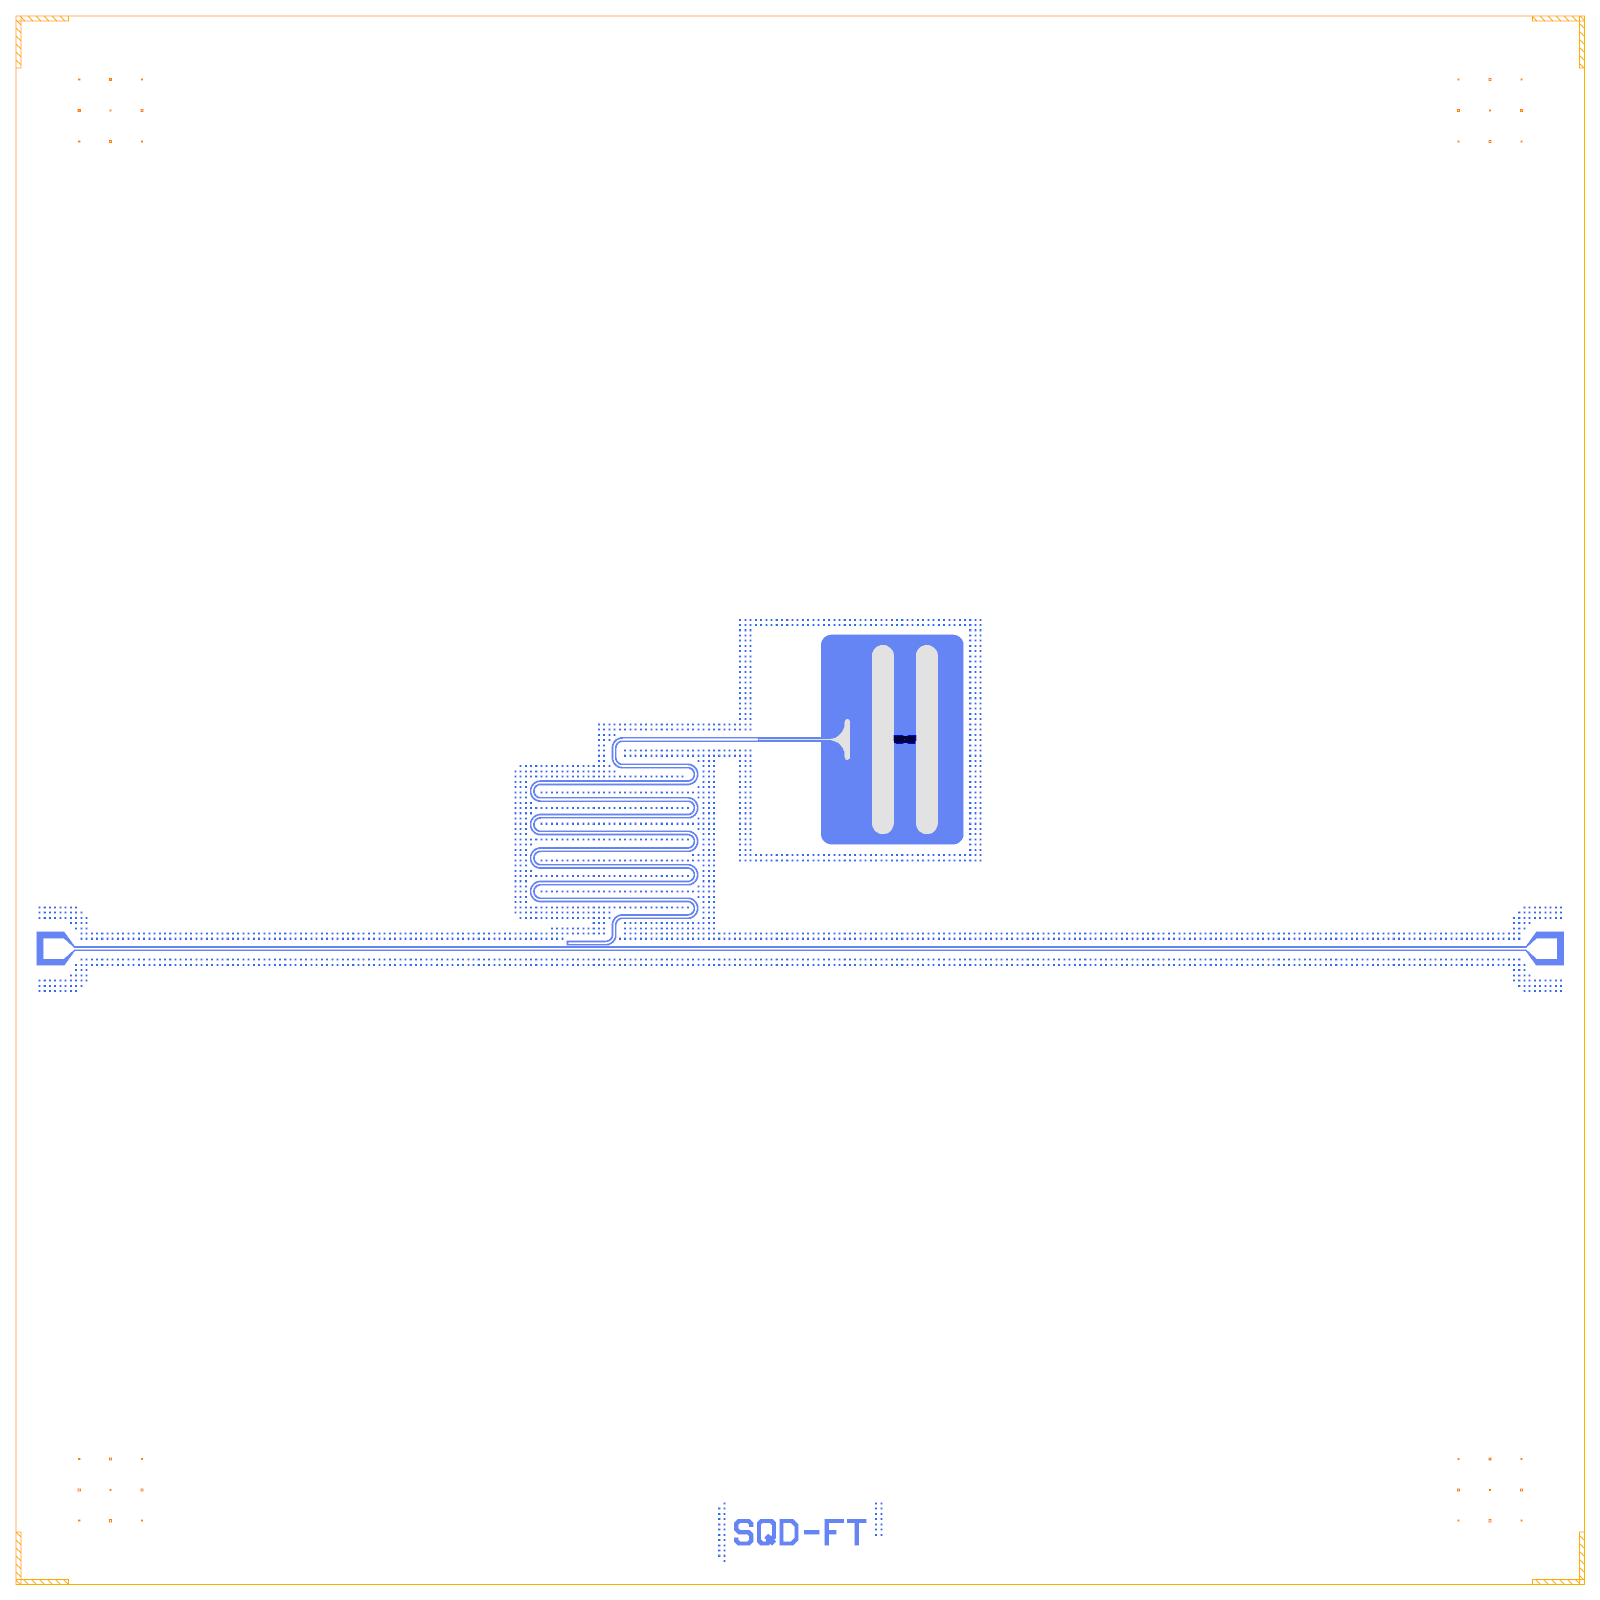

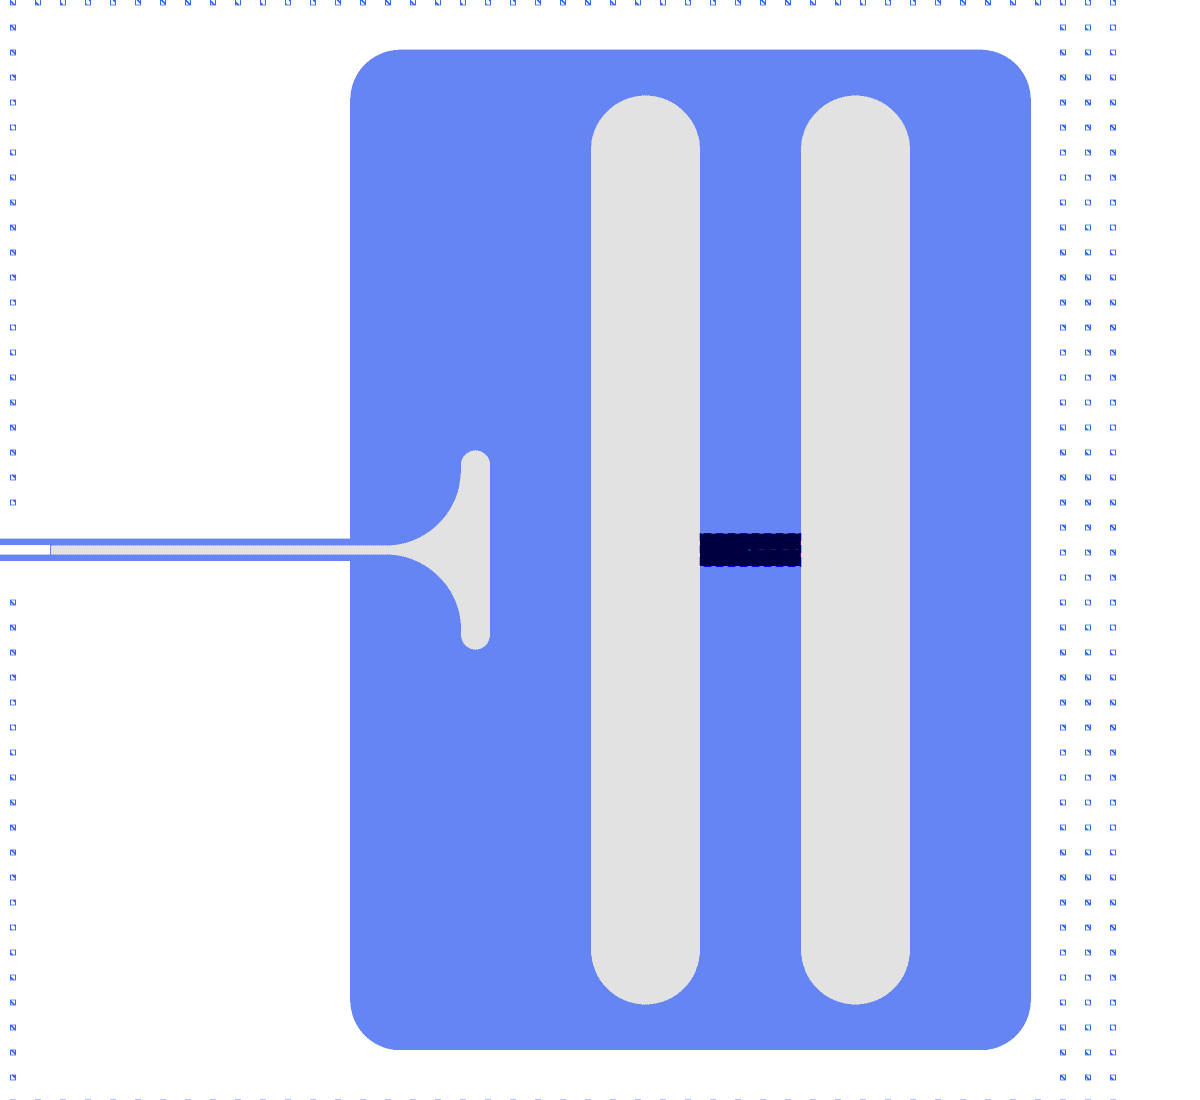

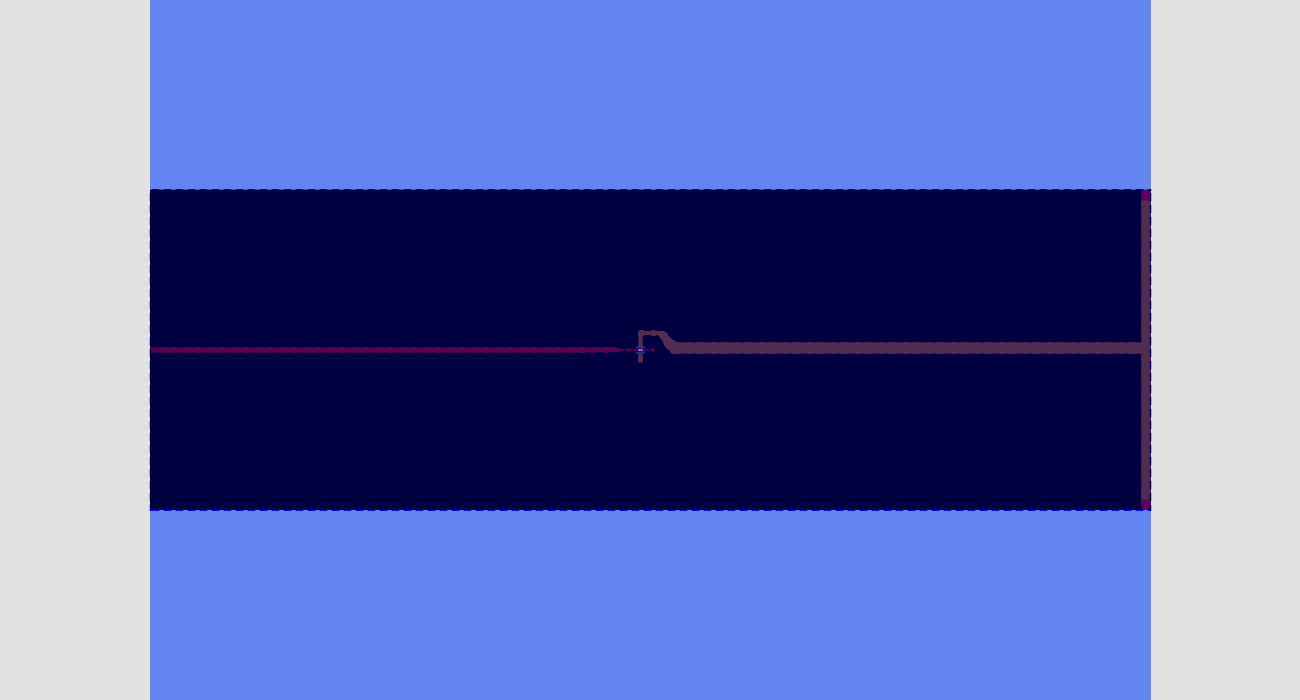

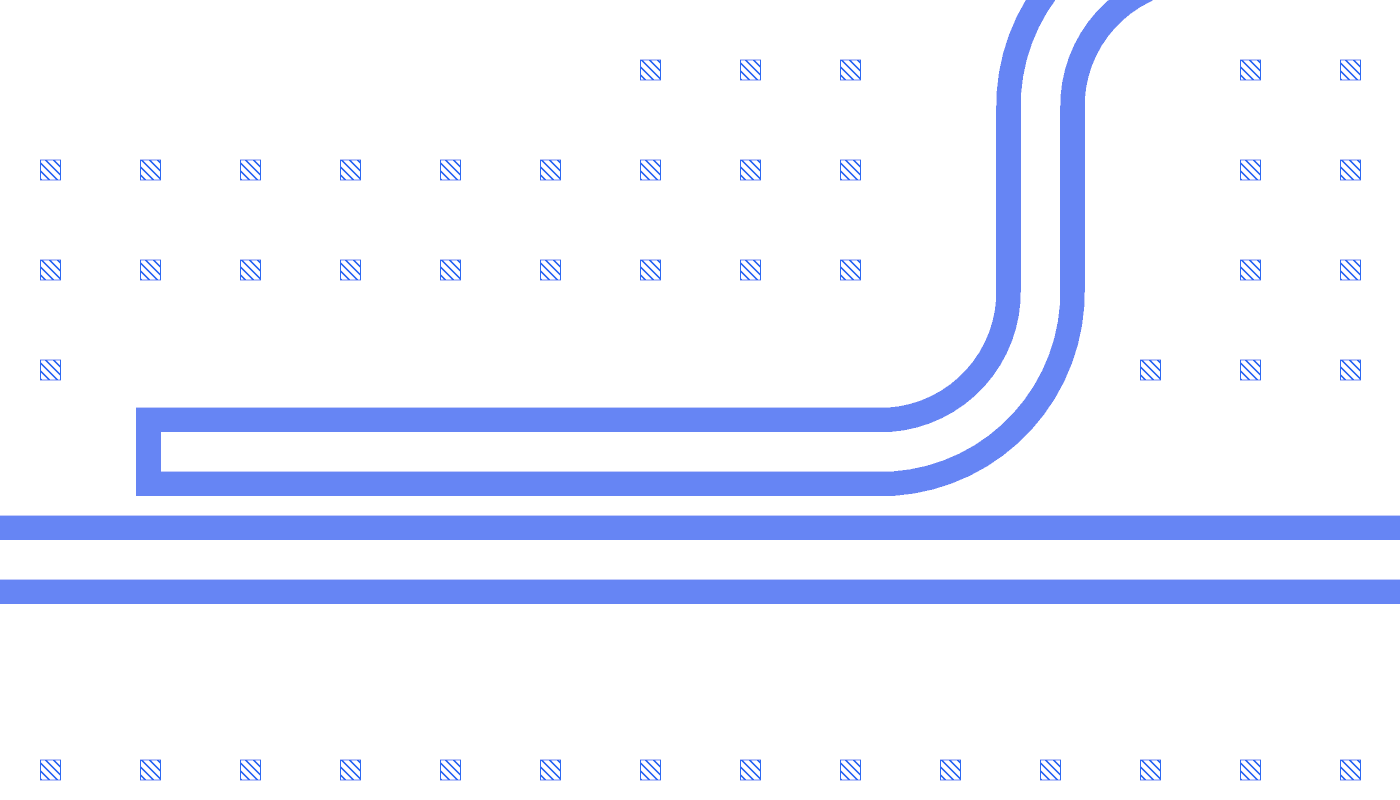

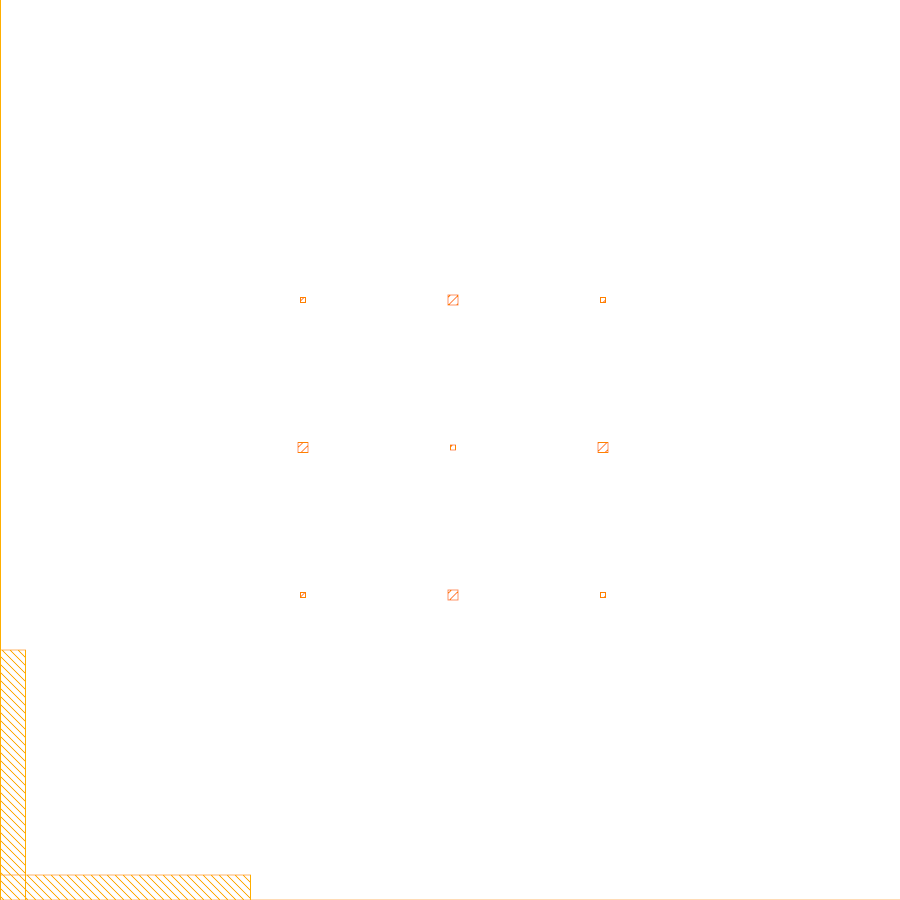

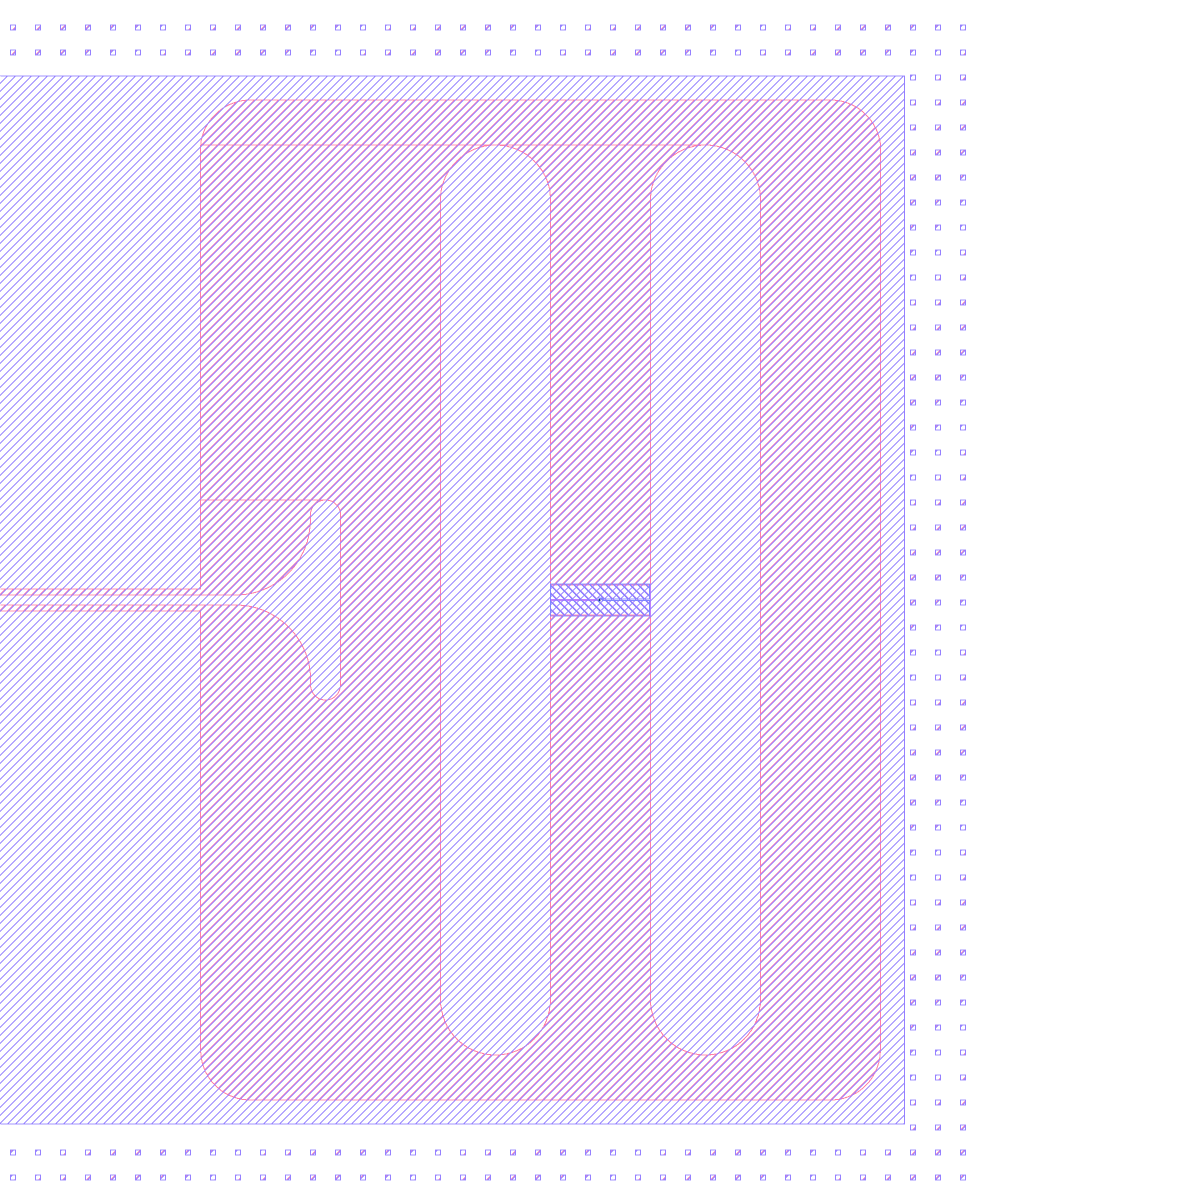

In [18]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
cx, cy = d.data["routes"]["R1"]["to"]["near"]               # centre of the coupled section (after centring)
show_snapshot(d, OUT / "floating_transmon.png", size=(1600, 1600))
show_snapshot(d, OUT / "floating_transmon_q1.png", box=(qx - 750, qy - 550, qx + 450, qy + 550), size=(1200, 1100), width=440)
show_snapshot(d, OUT / "floating_transmon_jj.png", box=(qx - 65, qy - 35, qx + 65, qy + 35), size=(1300, 700), width=360)
show_snapshot(d, OUT / "floating_transmon_coupler.png", box=(cx - 150, cy - 60, cx + 200, cy + 140), size=(1400, 800), width=480)
show_snapshot(d, OUT / "floating_transmon_frame.png", box=(-1750, -1750, -850, -850), size=(900, 900), width=300)
snap_file(Path("build") / "floating_transmon_fab.oas", OUT / "floating_transmon_fab_q1.png",
          box=(qx - 600, qy - 600, qx + 600, qy + 600), size=(1200, 1200), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | `TransmonTaperedInsets` with the source options and orientation; the 8960 µm λ/2 readout counted as in the source; the 220 µm / 5 µm open coupled section at the source's x; the targets; the eigenmode sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; the line's ends are bond pads on the die edges (outer etch 100 µm), so the line is 6.9 mm long; content centred (≈ 710 µm south); sapphire; the Quantcore trilayer junction sized for 4.5 GHz (R_n ≈ 72 kΩ); the PDK cheese band in the mask |
| **substituted** | `CoupledLineTee` + `RouteMeander` as one open hanger route (KQC meander); bond pads instead of the Palace ports on `OpenToGround`s |
| **PDK design warnings** | `pdk_rn` on Q1 (≈ 72 kΩ, sized for the source's target) |
| **FEM** | a Q3D C-matrix and an eigenmode / EPR job exported to `build/jobs/floating_transmon_Q1R1_*`, not solved here |